# Student Performance Analytics

**Scenario:** Learning Analytics Officer analysing anonymised student records.

This notebook addresses two problem areas:

1. **Performance Drivers** – Identify which socio-economic, demographic, or academic factors most strongly influence final grade (**G3**).
2. **At-Risk Students** – Detect students whose patterns indicate risk of under-performance (**G3 < 10**).

> **Submission note:** All results are displayed in the notebook (tables, metrics, plots). Key artefacts are also saved to an `outputs/` folder for convenience.


In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, r2_score,
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)

# Display settings
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

PASS_THRESHOLD = 10
TEST_SIZE = 0.2
RANDOM_STATE = 42

print("Imports loaded.")

Imports loaded.


## 1) Load Dataset & Basic Overview

Update `DATA_PATH` if your CSV is elsewhere.

In [80]:
from pathlib import Path
import os

DATA_PATH = "student_performance.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())

print("\nMissing values (top 15):")
display(df.isna().sum().sort_values(ascending=False).head(15))

if "course" in df.columns:
    print("\nCourse counts:")
    display(df["course"].value_counts())

Shape: (1044, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,course
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,Math
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,Math
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,Math
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,Math
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,Math



Missing values (top 15):


school      0
goout       0
nursery     0
higher      0
internet    0
romantic    0
famrel      0
freetime    0
Dalc        0
sex         0
Walc        0
health      0
absences    0
G1          0
G2          0
dtype: int64


Course counts:


course
Portuguese    649
Math          395
Name: count, dtype: int64

## 2) Preprocessing & Feature Engineering

- Encode binary variables to 0/1 (where applicable)
- One-hot encode nominal variables later in the modelling pipeline
- Create `absences_log = log1p(absences)` to reduce skew
- Create `delta_G2_G1 = G2 - G1` (academic trajectory)
- Create `at_risk = 1 if G3 < 10 else 0`

In [82]:
df = df.copy()

# Feature engineering
if "G1" in df.columns and "G2" in df.columns:
    df["delta_G2_G1"] = df["G2"] - df["G1"]

if "absences" in df.columns:
    df["absences_log"] = np.log1p(df["absences"])
else:
    df["absences_log"] = np.nan

# Binary target for at-risk detection
if "G3" not in df.columns:
    raise ValueError("Expected target column 'G3' not found.")
df["at_risk"] = (df["G3"] < PASS_THRESHOLD).astype(int)

# Column groups (based on dataset description)
nominal = ["school", "Mjob", "Fjob", "reason", "guardian", "course"]
binary = [
    "sex", "address", "famsize", "Pstatus",
    "schoolsup", "famsup", "paid", "activities",
    "nursery", "higher", "internet", "romantic"
]
numeric_ordinal = [
    "age", "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health",
    "absences_log"
]

# Add engineered and prior-grade features if present
for col in ["delta_G2_G1", "G1", "G2"]:
    if col in df.columns and col not in numeric_ordinal:
        numeric_ordinal.append(col)

# Keep only columns that exist (robust across variants)
def keep_existing(cols):
    return [c for c in cols if c in df.columns]

nominal = keep_existing(nominal)
binary = keep_existing(binary)
numeric_ordinal = keep_existing(numeric_ordinal)

# Map common binary text fields to numeric if needed
def safe_map(series, mapping):
    if pd.api.types.is_numeric_dtype(series):
        return series
    return series.map(mapping)

yn_cols = [c for c in ["schoolsup","famsup","paid","activities","nursery","higher","internet","romantic"] if c in df.columns]
for c in yn_cols:
    df[c] = safe_map(df[c], {"yes": 1, "no": 0})

if "sex" in df.columns:
    df["sex"] = safe_map(df["sex"], {"F": 0, "M": 1})
if "address" in df.columns:
    df["address"] = safe_map(df["address"], {"R": 0, "U": 1})
if "famsize" in df.columns:
    df["famsize"] = safe_map(df["famsize"], {"LE3": 0, "GT3": 1})
if "Pstatus" in df.columns:
    df["Pstatus"] = safe_map(df["Pstatus"], {"A": 0, "T": 1})

# Drop rows missing target
df = df.dropna(subset=["G3"]).reset_index(drop=True)

print("After cleaning shape:", df.shape)
print("At-risk rate:", round(df["at_risk"].mean(), 3))

display(df[[c for c in ["G3", "at_risk", "course", "G1", "G2", "absences", "absences_log"] if c in df.columns]].head())

After cleaning shape: (1044, 37)
At-risk rate: 0.22


,G3,at_risk,course,G1,G2,absences,absences_log
0,6,1,Math,5,6,6,1.945910
1,6,1,Math,5,5,4,1.609438
2,10,0,Math,7,8,10,2.397895
3,15,0,Math,15,14,2,1.098612
4,10,0,Math,6,10,4,1.609438


## 3) Exploratory Data Analysis (EDA)

This section provides descriptive statistics and visualisations for screenshots.

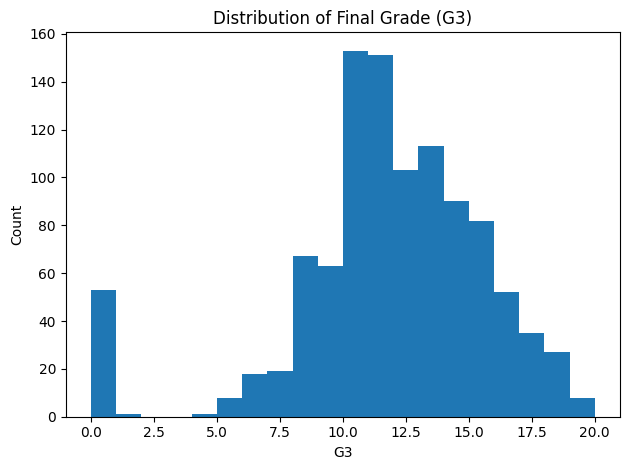

G3 Summary by course:


,count,mean,median,std
course,,,,
Portuguese,649,11.906009,12.0,3.230656
Math,395,10.415190,11.0,4.581443


Top correlations with G3:


G3              1.000000
G2              0.910743
G1              0.809142
delta_G2_G1     0.341705
higher          0.236578
Medu            0.201472
studytime       0.161629
Fedu            0.159796
address         0.117696
internet        0.107064
famrel          0.054461
nursery         0.039950
activities      0.033998
absences_log    0.015948
famsup          0.013313
Name: G3, dtype: float64

Most negative correlations with G3:


sex          -0.031472
absences     -0.045671
paid         -0.049388
famsize      -0.061209
freetime     -0.064890
schoolsup    -0.079346
health       -0.080079
goout        -0.097877
romantic     -0.098363
traveltime   -0.102627
Walc         -0.115740
age          -0.125282
Dalc         -0.129642
failures     -0.383145
at_risk      -0.729693
Name: G3, dtype: float64

In [84]:
# Distribution of G3
plt.figure()
plt.hist(df["G3"], bins=20)
plt.title("Distribution of Final Grade (G3)")
plt.xlabel("G3")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Summary by course
if "course" in df.columns:
    course_summary = df.groupby("course")["G3"].agg(["count", "mean", "median", "std"]).sort_values("mean", ascending=False)
    print("G3 Summary by course:")
    display(course_summary)

# Correlations with G3 for numeric columns
num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
corr = df[num_cols].corr(numeric_only=True)["G3"].sort_values(ascending=False)

print("Top correlations with G3:")
display(corr.head(15))

print("Most negative correlations with G3:")
display(corr.tail(15))

## 4) Helper: Get Feature Names After One-Hot Encoding

Needed to produce interpretable coefficient tables.

In [86]:
def get_feature_names(preprocessor: ColumnTransformer):
    names = []
    for name, transformer, cols in preprocessor.transformers_:
        if transformer == "passthrough":
            names.extend(list(cols))
        else:
            try:
                names.extend(list(transformer.get_feature_names_out(cols)))
            except Exception:
                names.extend([f"{name}__{c}" for c in cols])
    return names

print("Helper loaded.")

Helper loaded.


# Problem 1 - Performance Drivers

Two models are trained:

- **Model A (with G1/G2):** strong predictive model useful for early monitoring.
- **Model B (without G1/G2):** weaker predictive power but highlights more *actionable* drivers.

Metrics shown:
- **MAE** (Mean Absolute Error)
- **R²** (variance explained)

In [88]:
# Model A: Ridge regression WITH G1/G2
features_A = nominal + binary + numeric_ordinal
X = df[features_A]
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

preprocess_A = ColumnTransformer(
    transformers=[
        ("nom", OneHotEncoder(handle_unknown="ignore"), nominal),
        ("num", "passthrough", binary + numeric_ordinal),
    ]
)

reg_A = Pipeline(steps=[
    ("prep", preprocess_A),
    ("model", Ridge(alpha=1.0))
])

reg_A.fit(X_train, y_train)
pred_A = reg_A.predict(X_test)

mae_A = mean_absolute_error(y_test, pred_A)
r2_A = r2_score(y_test, pred_A)

print("Performance Drivers - Model A (WITH G1/G2)")
print(f"MAE: {mae_A:.3f}")
print(f"R² : {r2_A:.3f}")

# Coefficient table
fn_A = get_feature_names(preprocess_A)
coef_A = reg_A.named_steps["model"].coef_
coef_df_A = pd.DataFrame({"feature": fn_A, "coef": coef_A})
coef_df_A["abs_coef"] = coef_df_A["coef"].abs()
coef_df_A = coef_df_A.sort_values("abs_coef", ascending=False).drop(columns=["abs_coef"])

print("\nTop 25 most influential features (absolute coefficient):")
display(coef_df_A.head(25))

Performance Drivers - Model A (WITH G1/G2)
MAE: 1.005
R² : 0.811

Top 25 most influential features (absolute coefficient):


,feature,coef
48,G2,0.665582
47,G1,0.418388
45,absences_log,0.324791
20,course_Portuguese,0.312678
19,course_Math,-0.312678
38,failures,-0.308646
18,guardian_other,0.274872
46,delta_G2_G1,0.247193
7,Fjob_at_home,0.246499
11,Fjob_teacher,-0.228648


In [89]:
# Model B: Ridge regression WITHOUT G1/G2 (actionable drivers focus)
exclude = {"G1", "G2", "delta_G2_G1"}
numeric_B = [c for c in numeric_ordinal if c not in exclude]

features_B = nominal + binary + numeric_B
X = df[features_B]
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

preprocess_B = ColumnTransformer(
    transformers=[
        ("nom", OneHotEncoder(handle_unknown="ignore"), nominal),
        ("num", "passthrough", binary + numeric_B),
    ]
)

reg_B = Pipeline(steps=[
    ("prep", preprocess_B),
    ("model", Ridge(alpha=1.0))
])

reg_B.fit(X_train, y_train)
pred_B = reg_B.predict(X_test)

mae_B = mean_absolute_error(y_test, pred_B)
r2_B = r2_score(y_test, pred_B)

print("Performance Drivers - Model B (NO G1/G2)")
print(f"MAE: {mae_B:.3f}")
print(f"R² : {r2_B:.3f}")

# Coefficient table
fn_B = get_feature_names(preprocess_B)
coef_B = reg_B.named_steps["model"].coef_
coef_df_B = pd.DataFrame({"feature": fn_B, "coef": coef_B})
coef_df_B["abs_coef"] = coef_df_B["coef"].abs()
coef_df_B = coef_df_B.sort_values("abs_coef", ascending=False).drop(columns=["abs_coef"])

print("\nTop 25 most influential features (absolute coefficient):")
display(coef_df_B.head(25))

Performance Drivers - Model B (NO G1/G2)
MAE: 2.605
R² : 0.142

Top 25 most influential features (absolute coefficient):


,feature,coef
38,failures,-1.924730
30,higher,1.682555
25,schoolsup,-1.306378
20,course_Portuguese,0.981196
19,course_Math,-0.981196
3,Mjob_health,0.883067
11,Fjob_teacher,0.838353
18,guardian_other,0.823877
32,romantic,-0.648003
22,address,0.523287


# Problem 2 - At-Risk Students (Early Warning)

We define **at-risk** as `G3 < 10` and train an interpretable classifier (**Logistic Regression**).

Metrics shown:
- Confusion matrix
- Precision / Recall / F1
- ROC-AUC + ROC curve

> For early-warning in education, recall is often prioritised to reduce missed at-risk students.

At-Risk Detection (G3 < 10) - Logistic Regression (WITH G1/G2)

Confusion matrix [ [TN FP], [FN TP] ]:
[[143  20]
 [  6  40]]

Classification report:
              precision    recall  f1-score   support

           0      0.960     0.877     0.917       163
           1      0.667     0.870     0.755        46

    accuracy                          0.876       209
   macro avg      0.813     0.873     0.836       209
weighted avg      0.895     0.876     0.881       209

ROC-AUC: 0.966


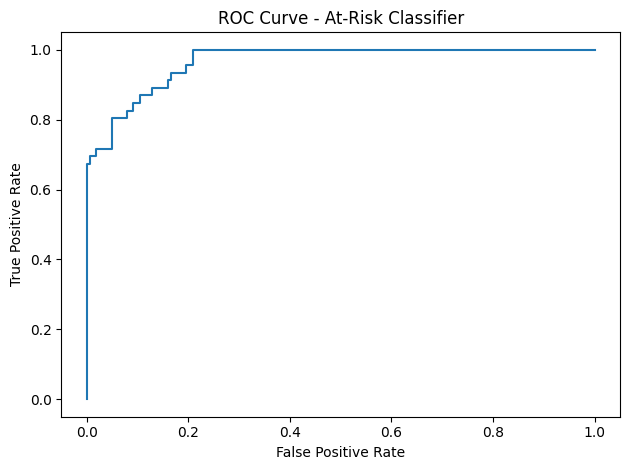

In [91]:
# Logistic regression classifier (WITH G1/G2 for strongest early warning)
X = df[features_A]
y = df["at_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

preprocess_cls = ColumnTransformer(
    transformers=[
        ("nom", OneHotEncoder(handle_unknown="ignore"), nominal),
        ("num", "passthrough", binary + numeric_ordinal),
    ]
)

clf = Pipeline(steps=[
    ("prep", preprocess_cls),
    ("model", LogisticRegression(max_iter=500, class_weight="balanced"))
])

clf.fit(X_train, y_train)

proba = clf.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"At-Risk Detection (G3 < {PASS_THRESHOLD}) - Logistic Regression (WITH G1/G2)")
print("\nConfusion matrix [ [TN FP], [FN TP] ]:")
cm = confusion_matrix(y_test, pred)
print(cm)

print("\nClassification report:")
report = classification_report(y_test, pred, digits=3)
print(report)

roc = roc_auc_score(y_test, proba)
print(f"ROC-AUC: {roc:.3f}")

# ROC curve plot
fpr, tpr, _ = roc_curve(y_test, proba)
plt.figure()
plt.plot(fpr, tpr)
plt.title("ROC Curve - At-Risk Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.tight_layout()
plt.show()

In [92]:
# Interpretable risk factors (coefficients)
fn = get_feature_names(preprocess_cls)
coef = clf.named_steps["model"].coef_.ravel()
coef_df = pd.DataFrame({"feature": fn, "coef": coef})
coef_df["abs_coef"] = coef_df["coef"].abs()
coef_df = coef_df.sort_values("abs_coef", ascending=False).drop(columns=["abs_coef"])

print("Top 30 strongest risk-related features (absolute coefficient):")
display(coef_df.head(30))

print("\nTop 15 features increasing risk (positive coef):")
display(coef_df.sort_values("coef", ascending=False).head(15))

print("\nTop 15 features decreasing risk (negative coef):")
display(coef_df.sort_values("coef", ascending=True).head(15))

Top 30 strongest risk-related features (absolute coefficient):


,feature,coef
48,G2,-1.366921
47,G1,-0.944444
24,Pstatus,0.794599
8,Fjob_health,0.675984
7,Fjob_at_home,-0.661877
36,traveltime,-0.627410
20,course_Portuguese,-0.619754
28,activities,0.615428
19,course_Math,0.611327
0,school_GP,-0.596194



Top 15 features increasing risk (positive coef):


,feature,coef
24,Pstatus,0.794599
8,Fjob_health,0.675984
28,activities,0.615428
19,course_Math,0.611327
1,school_MS,0.587767
3,Mjob_health,0.552048
12,reason_course,0.433459
29,nursery,0.422327
22,address,0.420986
21,sex,0.370689



Top 15 features decreasing risk (negative coef):


,feature,coef
48,G2,-1.366921
47,G1,-0.944444
7,Fjob_at_home,-0.661877
36,traveltime,-0.627410
20,course_Portuguese,-0.619754
0,school_GP,-0.596194
43,Walc,-0.468353
23,famsize,-0.446377
46,delta_G2_G1,-0.422476
39,famrel,-0.359454


## 5) Save Key Artefacts to `outputs/`

This is optional for marking, but useful for backup and quick export.

In [94]:
import os
from pathlib import Path

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Save EDA artefacts
corr.to_csv(OUT_DIR / "correlations_with_G3.csv")

# Save coefficients
coef_df_A.to_csv(OUT_DIR / "driver_model_coefficients_with_G1G2.csv", index=False)
coef_df_B.to_csv(OUT_DIR / "driver_model_coefficients_no_G1G2.csv", index=False)
coef_df.to_csv(OUT_DIR / "at_risk_coefficients.csv", index=False)

# Save classification report and confusion matrix
with open(OUT_DIR / "at_risk_classification_report.txt", "w", encoding="utf-8") as f:
    f.write(report)

pd.DataFrame(cm, index=["Actual_0", "Actual_1"], columns=["Pred_0", "Pred_1"]).to_csv(
    OUT_DIR / "at_risk_confusion_matrix.csv"
)

print(f"Saved artefacts to: {OUT_DIR.resolve()}")

Saved artefacts to: C:\Users\redav\Practice\DMTA\outputs


## 6) Task 1 Summary

In [96]:
summary = pd.DataFrame({
    "Item": [
        "Rows",
        "Mean G3",
        "At-risk rate (G3 < 10)",
        "Drivers Model A (WITH G1/G2) - MAE",
        "Drivers Model A (WITH G1/G2) - R²",
        "Drivers Model B (NO G1/G2) - MAE",
        "Drivers Model B (NO G1/G2) - R²",
        "At-risk classifier (WITH G1/G2) - ROC-AUC",
    ],
    "Value": [
        len(df),
        round(df["G3"].mean(), 3),
        round(df["at_risk"].mean(), 3),
        round(mae_A, 3),
        round(r2_A, 3),
        round(mae_B, 3),
        round(r2_B, 3),
        round(roc, 3),
    ]
})

display(summary)

,Item,Value
0,Rows,1044.000
1,Mean G3,11.342
2,At-risk rate (G3 < 10),0.220
3,Drivers Model A (WITH G1/G2) - MAE,1.005
4,Drivers Model A (WITH G1/G2) - R²,0.811
5,Drivers Model B (NO G1/G2) - MAE,2.605
6,Drivers Model B (NO G1/G2) - R²,0.142
7,At-risk classifier (WITH G1/G2) - ROC-AUC,0.966


## 7) Task 2 - Exploratory Data & Text‑Mining Analysis for Personalisation

This section extends the exploratory analysis by integrating **quantitative** variables (e.g., G1, G2, studytime, absences) with **qualitative / text-like** categorical variables (e.g., reason, guardian, parental occupations).

> **Note:** The dataset does not contain free-form natural language text; therefore, “text-mining” is operationalised as structured categorical text analysis (frequency patterns, group-wise performance lifts, and co-occurrence), which is appropriate for this dataset and common in educational datasets with survey-style fields.


### 7.1 Frequency Analysis of Text‑Like Variables

In [99]:
text_like_cols = [c for c in ["reason", "guardian", "Mjob", "Fjob", "school", "course"] if c in df.columns]

for c in text_like_cols:
    print(f"\n=== {c} (value counts) ===")
    display(df[c].value_counts(dropna=False).to_frame("count"))


=== reason (value counts) ===


,count
reason,
course,430
home,258
reputation,248
other,108



=== guardian (value counts) ===


,count
guardian,
mother,728
father,243
other,73



=== Mjob (value counts) ===


,count
Mjob,
other,399
services,239
at_home,194
teacher,130
health,82


... (2 outputs left out)


=== school (value counts) ===


,count
school,
GP,772
MS,272



=== course (value counts) ===


,count
course,
Portuguese,649
Math,395


### 7.2 Performance Patterns by Text‑Like Categories (Personalisation Signals)

In [101]:
def perf_by_category(col, target="G3"):
    out = df.groupby(col)[target].agg(["count", "mean", "median", "std"]).sort_values("mean", ascending=False)
    out["lift_vs_overall_mean"] = out["mean"] - df[target].mean()
    return out

for c in text_like_cols:
    print(f"\n=== {c} (G3 summary + lift) ===")
    display(perf_by_category(c).round(3))


=== reason (G3 summary + lift) ===


,count,mean,median,std,lift_vs_overall_mean
reason,,,,,
reputation,248,12.181,12.0,3.715,0.839
home,258,11.368,12.0,3.871,0.026
course,430,10.965,11.0,3.880,-0.377
other,108,10.852,11.0,3.864,-0.490



=== guardian (G3 summary + lift) ===


,count,mean,median,std,lift_vs_overall_mean
guardian,,,,,
father,243,11.642,12.0,3.777,0.300
mother,728,11.367,11.0,3.885,0.025
other,73,10.096,11.0,3.761,-1.246



=== Mjob (G3 summary + lift) ===


,count,mean,median,std,lift_vs_overall_mean
Mjob,,,,,
health,82,12.683,13.0,3.545,1.341
teacher,130,12.208,12.5,3.957,0.866
services,239,11.661,12.0,3.853,0.319
other,399,11.018,11.0,3.812,-0.324
at_home,194,10.469,11.0,3.786,-0.873


... (2 outputs left out)


=== school (G3 summary + lift) ===


,count,mean,median,std,lift_vs_overall_mean
school,,,,,
GP,772,11.633,12.0,3.809,0.291
MS,272,10.515,10.0,3.909,-0.827



=== course (G3 summary + lift) ===


,count,mean,median,std,lift_vs_overall_mean
course,,,,,
Portuguese,649,11.906,12.0,3.231,0.564
Math,395,10.415,11.0,4.581,-0.927


### 7.3 Visualisation: Grade Distributions Across Categorical Groups

C:\Users\redav\AppData\Local\Temp\ipykernel_18964\1677528785.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=[str(lv) for lv in levels])


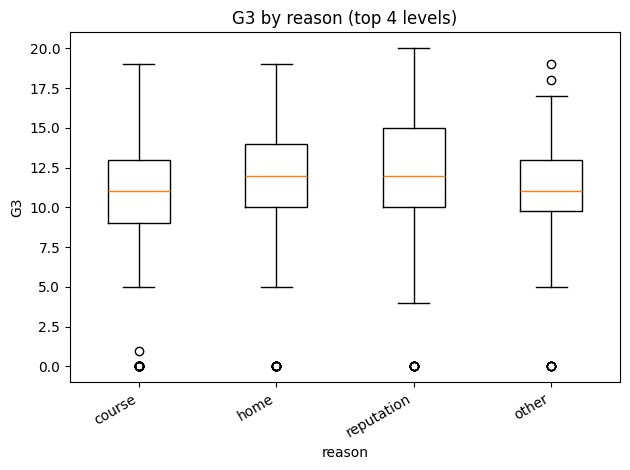

C:\Users\redav\AppData\Local\Temp\ipykernel_18964\1677528785.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=[str(lv) for lv in levels])


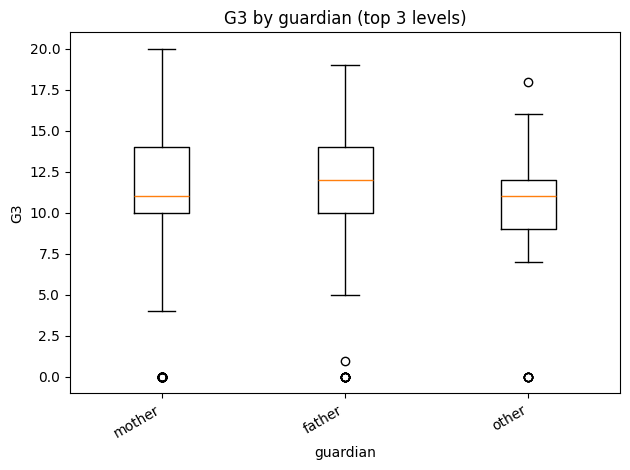

C:\Users\redav\AppData\Local\Temp\ipykernel_18964\1677528785.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=[str(lv) for lv in levels])


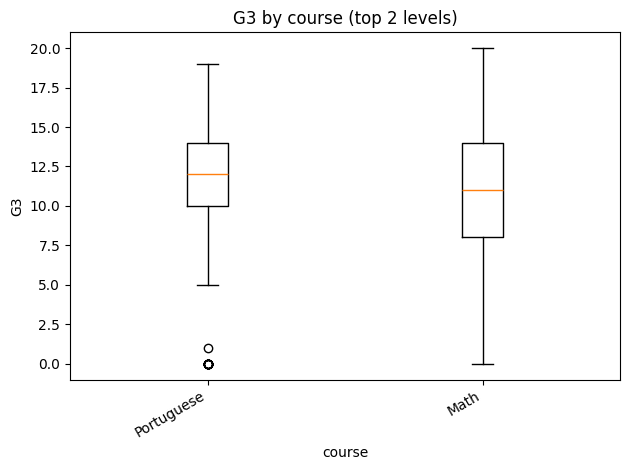

In [103]:
def boxplot_by_category(col, target="G3", max_levels=12):
    # Limit levels for readability in screenshots
    levels = df[col].value_counts().head(max_levels).index.tolist()
    d = df[df[col].isin(levels)]
    groups = [d[d[col] == lv][target].dropna().values for lv in levels]
    plt.figure()
    plt.boxplot(groups, labels=[str(lv) for lv in levels])
    plt.title(f"{target} by {col} (top {len(levels)} levels)")
    plt.xlabel(col)
    plt.ylabel(target)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

for c in [x for x in ["reason", "guardian", "course"] if x in df.columns]:
    boxplot_by_category(c)

### 7.4 Co‑Occurrence Patterns (Context + Support)

In [105]:
# Example: guardian vs educational support indicators (if present)
if "guardian" in df.columns and "schoolsup" in df.columns:
    print("Guardian × School Support (proportions):")
    tab = pd.crosstab(df["guardian"], df["schoolsup"], normalize="index")
    display(tab.round(3))

# Example: reason vs course (if present)
if "reason" in df.columns and "course" in df.columns:
    print("Reason × Course (counts):")
    display(pd.crosstab(df["reason"], df["course"]))

# Example: parental education vs risk (if present)
if "Medu" in df.columns:
    print("Mother Education (Medu) × At-Risk (proportions):")
    display(pd.crosstab(df["Medu"], df["at_risk"], normalize="index").round(3))

Guardian × School Support (proportions):


schoolsup,0,1
guardian,,
father,0.864,0.136
mother,0.889,0.111
other,0.932,0.068


Reason × Course (counts):


course,Math,Portuguese
reason,,
course,145,285
home,109,149
other,36,72
reputation,105,143


Mother Education (Medu) × At-Risk (proportions):


at_risk,0,1
Medu,,
0,0.889,0.111
1,0.693,0.307
2,0.782,0.218
3,0.761,0.239
4,0.846,0.154


### 7.5 Simple Personalisation Segments (Rule‑Based Profiles)

In [127]:
# Create a few interpretable segments to support personalised interventions
seg = df.copy()

# Basic bands (tune thresholds as needed)
if "studytime" in seg.columns:
    seg["study_band"] = pd.cut(seg["studytime"], bins=[0,1,2,3,4], labels=["<2h", "2-5h", "5-10h", ">10h"])
if "absences" in seg.columns:
    seg["absence_band"] = pd.cut(seg["absences"], bins=[-1, 0, 5, 10, 10**9], labels=["0", "1-5", "6-10", "11+"])

cols = [c for c in ["study_band", "absence_band"] if c in seg.columns]
if len(cols) == 2:
    segment_summary = seg.groupby(cols).agg(
        n=("G3","count"),
        mean_G3=("G3","mean"),
        risk_rate=("at_risk","mean")
    ).reset_index().sort_values(["risk_rate","mean_G3"], ascending=[False, True])
    print("Segment summary (study band × absence band):")
    display(segment_summary.round(3))
else:
    print("Not enough columns present to build the default segmentation table.")

Segment summary (study band × absence band):


,study_band,absence_band,n,mean_G3,risk_rate
3,<2h,11+,40,9.750,0.450
0,<2h,0,100,9.200,0.340
7,2-5h,11+,66,10.515,0.333
6,2-5h,6-10,85,11.176,0.282
11,5-10h,11+,8,11.500,0.250
4,2-5h,0,174,11.241,0.207
1,<2h,1-5,107,11.411,0.206
13,>10h,1-5,21,12.286,0.190
2,<2h,6-10,70,11.757,0.186
8,5-10h,0,65,12.323,0.169


## 8) Save Task 2 Artefacts to `outputs/`

In [109]:
# Save key Task 2 tables for backup (optional)
from pathlib import Path
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

for c in text_like_cols:
    df[c].value_counts(dropna=False).to_frame("count").to_csv(OUT_DIR / f"task2_freq_{c}.csv")
    perf_by_category(c).to_csv(OUT_DIR / f"task2_perf_{c}.csv")

print("Task 2 artefacts saved (frequency + performance tables).")

Task 2 artefacts saved (frequency + performance tables).
